# Minimum weight perfect matching implementation

**Reference paper**: https://arxiv.org/pdf/2105.13082

### First implementation: k=1 repetition code

Num qubits `n=3`; check matrix `H=[[1, 1, 0]; [0, 1, 1]]` rank 2; `n - rank(H) = 1` data qubit

In [ ]:
# first construct check matrix for simple repetition code
import numpy as np
from pymatching import Matching

H = np.array([
    [1, 1, 0],
    [0, 1, 1]
    ])
ERROR_PROB = 0.1

# construct pymatching Matching object from given H and weights using given error probability
weights = np.ones(H.shape[1] * np.log((1 - ERROR_PROB) / ERROR_PROB))
m = Matching.from_check_matrix(H, weights)

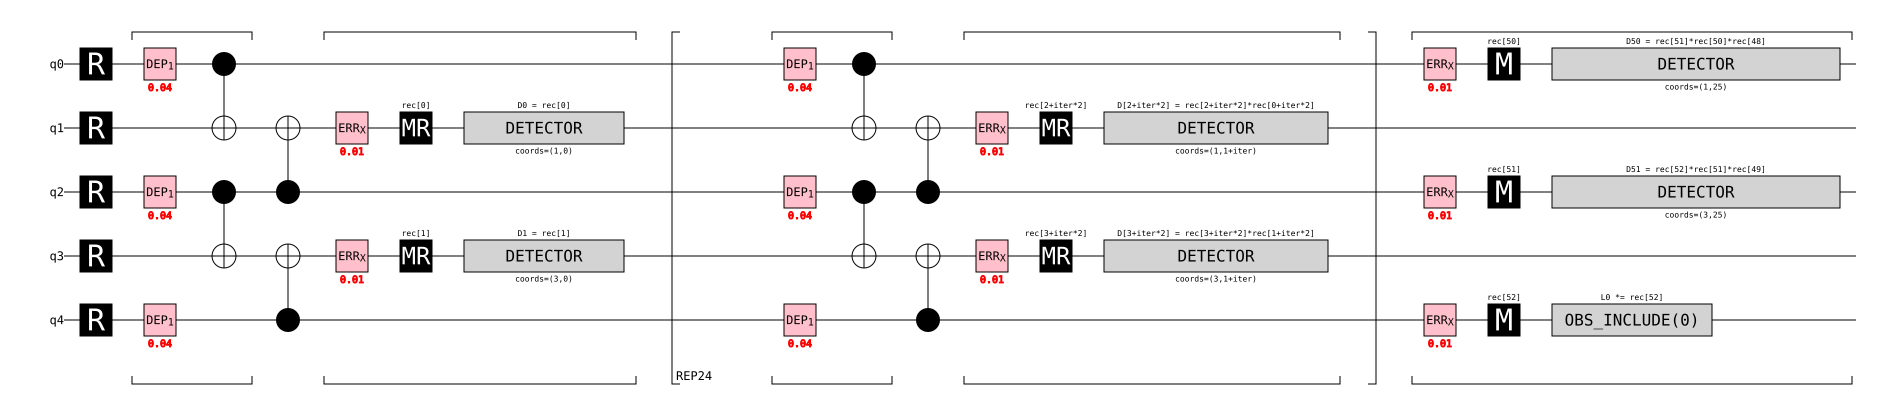

In [8]:
# construct stim simulator for data generation. repetition code circuit d=3
import stim
repetition_ckt = stim.Circuit.generated(
    "repetition_code:memory",
    rounds=25,
    distance=3,
    before_measure_flip_probability=0.01,
    before_round_data_depolarization=0.04
)
repetition_ckt.diagram('timeline-svg')

In [ ]:
# show errors as 1 when simulating the circuit. tracks each channel
sampler = repetition_ckt.compile_sampler()
result = sampler.sample(shots=3)[0]
print("".join("1" if e else "_" for e in result))

_1__________11_111111_1__1_1_1_1_1_111_111_1_1_1_111_


In [ ]:
# now show errors tracking the detector
# results are much more sparse because we are tracking detected errors, not just whether error happens or not on channel
# foundation for error correction: flips come in pairs
detector_sampler = repetition_ckt.compile_detector_sampler()
result = detector_sampler.sample(shots=3)[0]
print("".join("1" if e else "_" for e in result))

____________________________11______________________
